# 10. 데이터 한계 vs 모델 한계 가르기 (Phase A-4-2)

세션 45/46에서 발견한 **라벨 이동 100% 수렴 패턴**의 메커니즘을 데이터 차원에서 검증.

## 가르려는 것
- **데이터 한계**: K-code 학습 ROI 자체에서 두 클래스가 각인으로 변별 불가능 (각인 흐림/없음/유사) → 모델이 못 볼 수밖에 없음
- **모델 한계**: 학습 ROI에서 각인 변별 가능한데 모델이 안 봄 → 학습 사양/loss/구조 처방 필요

## 검증 대상 (세션 45 발견 3쌍)
| 후퇴 클래스 (학습 GT) | v2 top1 오답 |
|---|---|
| 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물) (630) | 리피토정 20mg |
| 디카테오엘씨정 10mg/병 (434) | 디카테오정 |
| 비유피-4정 20mg (290) | 베시케어정 10mg |

## 방법
1. 6 클래스 (후퇴 3 + 오답 3) clean_df 메타 검증 (drug_shape, color_class1, train_ann, val_ann)
2. 각 클래스 K-code ROI 추출 (train + val 통합)
3. 3쌍 ROI 시각 비교 (각인 변별 가능한지 사람 눈으로)
4. 각인 가시성 정량 (세션 40 M2: 원본 + imgsz 1280 다운→업 Laplacian)
5. 메타 변별성 vs 각인 변별성 비교 → 종합 판정

## 판정 기준
- **데이터 한계**: 두 클래스 각인이 imgsz 1280 다운→업에서도 사람 눈에 거의 구분 안 됨 + 메타(shape/color)도 동일 → 모델 무죄
- **모델 한계**: 두 클래스 각인이 imgsz 1280에서 명확히 다름 → 모델이 봤어야 함, 안 본 것
- **혼합**: 일부 페어는 데이터 한계, 일부는 모델 한계

In [1]:
import os
import sys
import json
import unicodedata
import numpy as np
import pandas as pd
import cv2
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib

# 한글 폰트
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

# 경로 (메모리 박제값)
ROOT = Path(r'D:\pill_detection')
CLEAN_DF_PATH = ROOT / 'data' / 'team_preprocessed' / 'clean_df.csv'
IMG_TRAIN = ROOT / 'data' / 'dataset_yolo' / 'images' / 'train'
IMG_VAL = ROOT / 'data' / 'dataset_yolo' / 'images' / 'val'
LBL_TRAIN = ROOT / 'data' / 'dataset_yolo' / 'labels' / 'train'
LBL_VAL = ROOT / 'data' / 'dataset_yolo' / 'labels' / 'val'

OUT_DIR = ROOT / 'analysis' / 'figures_causality'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_JSON = ROOT / 'analysis' / '10_causality_results.json'

# 한글 경로 호환 imread
def imread_kr(path):
    arr = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)

# NFC 정규화 (메모리 박제: NBSP 등 처리)
def nfc(s):
    if pd.isna(s):
        return s
    return unicodedata.normalize('NFC', str(s)).rstrip(' \t\xa0\u3000')


# 검증 대상 6 클래스 (3쌍)
TARGET_PAIRS = [
    ('동아오팔몬정', '리피토정'),
    ('디카테오엘씨정', '디카테오정'),
    ('비유피-4정', '베시케어정'),
]

# 경로 sanity
print('=== 경로 검증 ===')
for p in [CLEAN_DF_PATH, IMG_TRAIN, IMG_VAL, LBL_TRAIN, LBL_VAL]:
    exists = p.exists()
    n = len(list(p.iterdir())) if (exists and p.is_dir()) else None
    print(f'  {p}: {"✓" if exists else "✗"}' + (f' ({n}개)' if n else ''))

print(f'\n출력 폴더: {OUT_DIR}')
print(f'결과 JSON: {RESULTS_JSON}')
print(f'matplotlib font: {matplotlib.rcParams["font.family"]}')

=== 경로 검증 ===
  D:\pill_detection\data\team_preprocessed\clean_df.csv: ✓
  D:\pill_detection\data\dataset_yolo\images\train: ✓ (8302개)
  D:\pill_detection\data\dataset_yolo\images\val: ✓ (2090개)
  D:\pill_detection\data\dataset_yolo\labels\train: ✓ (8302개)
  D:\pill_detection\data\dataset_yolo\labels\val: ✓ (2090개)

출력 폴더: D:\pill_detection\analysis\figures_causality
결과 JSON: D:\pill_detection\analysis\10_causality_results.json
matplotlib font: ['Malgun Gothic']


## 1. clean_df 로드 + 6 클래스 키워드 매칭

세션 45에서 발견한 후퇴 3쌍의 정확한 클래스 이름을 clean_df에서 검색.

부분 키워드로 검색 후 매칭되는 클래스 이름 후보 출력 → 다음 셀에서 정확한 이름 6개 확정.

NBSP/NFC 이슈는 세션 44에서 발견됨 (협업 원칙 83). `nfc()` 함수로 정규화.

In [2]:
# clean_df 로드
clean_df = pd.read_csv(CLEAN_DF_PATH)
print(f'clean_df shape: {clean_df.shape}')
print(f'columns: {list(clean_df.columns)}\n')

# dl_name NFC 정규화 (NBSP 처리)
clean_df['dl_name_nfc'] = clean_df['dl_name'].apply(nfc)

# 6 클래스 검색 (부분 일치)
target_classes = []
for kw_a, kw_b in TARGET_PAIRS:
    for kw in [kw_a, kw_b]:
        matches = clean_df[clean_df['dl_name_nfc'].str.contains(kw, na=False, regex=False)]
        unique_names = matches['dl_name_nfc'].unique()
        if len(unique_names) == 0:
            print(f'⚠️  "{kw}" 검색 결과 0건')
            continue
        target_classes.append((kw, unique_names))

# 검색 결과 요약
print('=== 키워드별 매칭 클래스 ===')
for kw, names in target_classes:
    print(f'\n[{kw}] {len(names)}개:')
    for n in names[:5]:
        cnt = (clean_df['dl_name_nfc'] == n).sum()
        print(f'  "{n}" ({cnt} ann)')
    if len(names) > 5:
        print(f'  ... 외 {len(names)-5}개')

clean_df shape: (39864, 45)
columns: ['file_name', 'image_id', 'width', 'height', 'category_id', 'dl_name', 'dl_name_en', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area', 'color_class1', 'color_class2', 'drug_shape', 'print_front', 'print_back', 'form_code_name', 'di_etc_otc_code', 'camera_la', 'leng_long', 'leng_short', 'thick', 'class_idx', 'class_name', 'bbox_cx', 'bbox_cy', 'bbox_cx_n', 'bbox_cy_n', 'bbox_w_n', 'bbox_h_n', 'back_color', 'di_class_no', 'dl_company', 'dl_idx', 'dl_mapping_code', 'dl_material', 'drug_dir', 'image_exists', 'json_path', 'light_color', 'set_id', 'source', 'category_id_merged', 'final_class_idx_merged']

=== 키워드별 매칭 클래스 ===

[동아오팔몬정] 1개:
  "동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)" (630 ann)

[리피토정] 1개:
  "리피토정 20mg" (807 ann)

[디카테오엘씨정] 1개:
  "디카테오엘씨정 10mg/병" (434 ann)

[디카테오정] 1개:
  "디카테오정" (436 ann)

[비유피-4정] 1개:
  "비유피-4정 20mg" (290 ann)

[베시케어정] 1개:
  "베시케어정 10mg" (79 ann)


C:\Users\tran6\AppData\Local\Temp\ipykernel_1168\1797250636.py:2: DtypeWarning: Columns (38) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_df = pd.read_csv(CLEAN_DF_PATH)


## 2. 6 클래스 메타 정보 추출

각 클래스의 train/val 분포 + 시각 메타(drug_shape, color_class1, color_class2) + 각인 정보(print_front, print_back) 추출.

핵심 비교:
- **메타 변별성**: drug_shape, color_class1이 두 클래스 간 다르면 → 모델이 형태/색만으로 변별 가능 (각인 안 봐도 됨)
- **메타 동일**: 형태/색 같음 → 각인이 변별 핵심 → 모델이 각인 안 보면 라벨 이동 발생

세션 38 진단 #6에서 "분류기가 각인 학습 못 함" 가설 제기, 세션 44에서 PTP/캡슐/장방형 단축경로 모두 기각, 세션 45에서 라벨 이동 100% 수렴 발견 → 메타 동일하면 가설 1 추가 정합 신호.

In [3]:
# 6 클래스 정확한 이름 확정
PAIR_NAMES = [
    ('동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)', '리피토정 20mg'),
    ('디카테오엘씨정 10mg/병', '디카테오정'),
    ('비유피-4정 20mg', '베시케어정 10mg'),
]

ALL_CLASSES = [n for pair in PAIR_NAMES for n in pair]

# 메타 정보 추출 함수
META_COLS = ['drug_shape', 'color_class1', 'color_class2', 'print_front', 'print_back',
             'form_code_name', 'leng_long', 'leng_short', 'thick']

def get_class_meta(name):
    rows = clean_df[clean_df['dl_name_nfc'] == name]
    n_total = len(rows)
    
    # train/val split (file_name 기준)
    if 'source' in rows.columns:
        n_train = (rows['source'] == 'train').sum() if rows['source'].notna().any() else None
        n_val = (rows['source'] == 'val').sum() if rows['source'].notna().any() else None
    else:
        n_train = n_val = None
    
    # 메타 mode (가장 흔한 값)
    meta = {}
    for col in META_COLS:
        if col in rows.columns:
            vals = rows[col].dropna()
            if len(vals) > 0:
                if vals.dtype == 'object':
                    meta[col] = vals.mode().iloc[0]
                else:
                    meta[col] = round(vals.mean(), 2)
            else:
                meta[col] = None
    
    return {
        'name': name,
        'n_total': n_total,
        'n_train': int(n_train) if n_train is not None else None,
        'n_val': int(n_val) if n_val is not None else None,
        **meta,
    }


# 6 클래스 메타 출력
class_metas = {n: get_class_meta(n) for n in ALL_CLASSES}

# 표 형태 출력
import pandas as pd
meta_df = pd.DataFrame(class_metas).T
print('=== 6 클래스 메타 정보 ===')
print(meta_df.to_string())

# 페어별 비교
print('\n\n=== 페어별 메타 변별성 ===')
for a, b in PAIR_NAMES:
    print(f'\n[{a[:25]}] vs [{b[:25]}]')
    for col in ['drug_shape', 'color_class1', 'color_class2', 'leng_long', 'leng_short', 'thick']:
        va = class_metas[a].get(col)
        vb = class_metas[b].get(col)
        same = '✗ 동일' if va == vb else '✓ 다름'
        print(f'  {col:15s}: {str(va):20s} vs {str(vb):20s}  → {same}')
    print(f'  print_front    : {str(class_metas[a].get("print_front")):20s} vs {str(class_metas[b].get("print_front")):20s}')
    print(f'  print_back     : {str(class_metas[a].get("print_back")):20s} vs {str(class_metas[b].get("print_back")):20s}')

=== 6 클래스 메타 정보 ===
                                                        name n_total n_train n_val drug_shape color_class1 color_class2 print_front print_back form_code_name leng_long leng_short thick
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)  동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)     630       0     0         원형           하양         None         OMT       None             나정      6.63       6.63  2.27
리피토정 20mg                                          리피토정 20mg     807       0     0         원형           하양         None         ATV         20          필름코팅정       7.5        7.5   4.5
디카테오엘씨정 10mg/병                                디카테오엘씨정 10mg/병     434       0     0        장방형           하양         None     마크분할선CT         LC             나정      15.6        7.1   4.8
디카테오정                                                  디카테오정     436       0     0        장방형           하양         None     마크분할선CT       None             나정     21.81       9.31  7.56
비유피-4정 20mg                                      비유피-4정

## 3. K-code ROI 추출 함수 + train/val split 정확한 카운트

clean_df의 source 컬럼이 비어있어서 file_name 기준으로 train/val 폴더 매칭하여 정확한 split 카운트 재산출.

ROI 추출 함수: bbox 좌표로 알약 영역만 crop. 각인 영역 보존 위해 padding 0.

추출된 ROI는 셀 5(시각 비교)와 셀 7(각인 정량 측정)에서 사용.

In [4]:
# clean_df의 file_name 기준으로 train/val 폴더 매칭
train_files = set(f.name for f in IMG_TRAIN.iterdir())
val_files = set(f.name for f in IMG_VAL.iterdir())

print(f'train 폴더: {len(train_files)}장')
print(f'val 폴더: {len(val_files)}장')

# clean_df 행마다 split 결정
def determine_split(row):
    fn = row['file_name']
    if fn in train_files:
        return 'train'
    elif fn in val_files:
        return 'val'
    else:
        return 'unknown'

clean_df['split'] = clean_df.apply(determine_split, axis=1)
print(f'\nclean_df split 분포: {clean_df["split"].value_counts().to_dict()}')

# 6 클래스 정확한 split 카운트
print('\n=== 6 클래스 train/val split ===')
print(f'{"클래스":<50s} {"train":>6s} {"val":>5s} {"unknown":>8s} {"total":>6s}')
for cls in ALL_CLASSES:
    rows = clean_df[clean_df['dl_name_nfc'] == cls]
    n_train = (rows['split'] == 'train').sum()
    n_val = (rows['split'] == 'val').sum()
    n_unknown = (rows['split'] == 'unknown').sum()
    print(f'{cls[:48]:<50s} {n_train:>6d} {n_val:>5d} {n_unknown:>8d} {len(rows):>6d}')


# ROI 추출 함수
def extract_roi(row, pad=0):
    """clean_df 한 행에서 ROI 추출. 한글 경로 + bbox crop."""
    fn = row['file_name']
    split = row['split']
    if split == 'train':
        img_path = IMG_TRAIN / fn
    elif split == 'val':
        img_path = IMG_VAL / fn
    else:
        return None
    
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        return None
    
    H, W = img_bgr.shape[:2]
    x = int(row['bbox_x'])
    y = int(row['bbox_y'])
    w = int(row['bbox_w'])
    h = int(row['bbox_h'])
    
    x1 = max(0, x - pad)
    y1 = max(0, y - pad)
    x2 = min(W, x + w + pad)
    y2 = min(H, y + h + pad)
    
    roi = img_bgr[y1:y2, x1:x2]
    return cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)


# sanity: 첫 클래스에서 1개 추출 시도
test_cls = ALL_CLASSES[0]
test_rows = clean_df[clean_df['dl_name_nfc'] == test_cls]
test_row = test_rows.iloc[0]
test_roi = extract_roi(test_row)
if test_roi is not None:
    print(f'\nsanity: {test_cls[:30]} ROI shape = {test_roi.shape}')
else:
    print(f'\n⚠️  sanity 실패: {test_cls}')

train 폴더: 8302장
val 폴더: 2090장

clean_df split 분포: {'train': 31844, 'val': 8020}

=== 6 클래스 train/val split ===
클래스                                                 train   val  unknown  total
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                         508   122        0    630
리피토정 20mg                                             643   164        0    807
디카테오엘씨정 10mg/병                                        366    68        0    434
디카테오정                                                 328   108        0    436
비유피-4정 20mg                                           239    51        0    290
베시케어정 10mg                                             52    27        0     79

sanity: 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물) ROI shape = (165, 172, 3)


## 4. 3쌍 ROI 시각 비교 (사람 눈으로 변별성 확인)

각 페어별 두 클래스 ROI 6장씩 나란히 표시. 같은 imgsz로 리사이즈해서 변별 조건 동일하게 맞춤.

목적:
- **사람 눈에 두 클래스가 각인/색/크기로 변별 가능한가**
- 변별 가능 → 모델이 못 본 것 (모델 한계)
- 변별 불가능 → 데이터 자체가 안 됨 (데이터 한계)

이번 셀은 원본 ROI (다운샘플 X). 다음 셀에서 imgsz 1280 다운→업 적용본 비교.

동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)            샘플 6장
리피토정 20mg                                샘플 6장
디카테오엘씨정 10mg/병                           샘플 6장
디카테오정                                    샘플 6장
비유피-4정 20mg                              샘플 6장
베시케어정 10mg                               샘플 6장


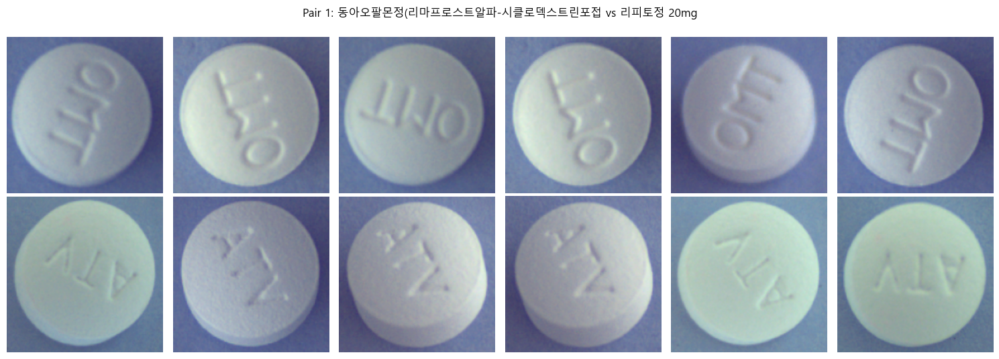

저장: D:\pill_detection\analysis\figures_causality\10_pair1_original.png


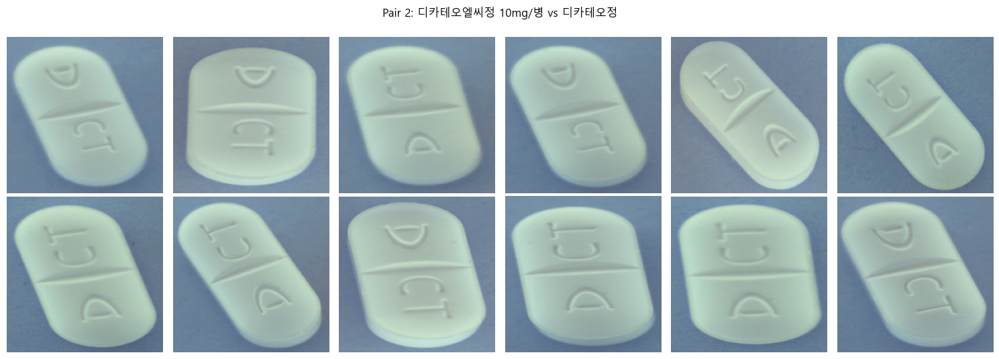

저장: D:\pill_detection\analysis\figures_causality\10_pair2_original.png


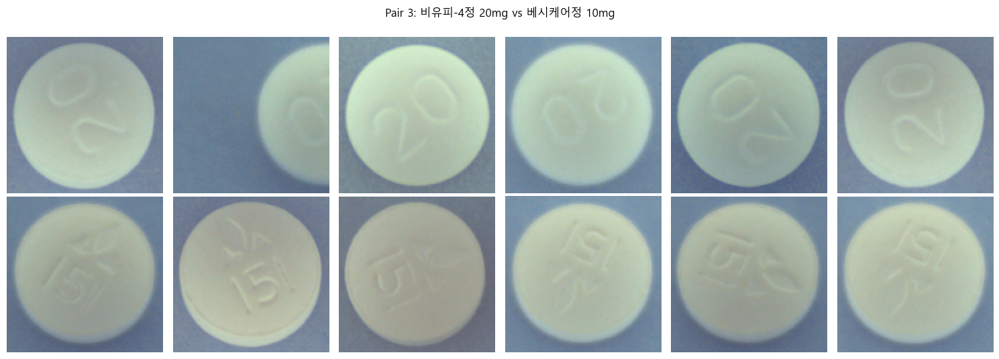

저장: D:\pill_detection\analysis\figures_causality\10_pair3_original.png


In [5]:
import random
random.seed(2026)

# 각 클래스에서 N개 무작위 샘플 (train+val 통합)
N_PER_CLASS = 6

samples_by_class = {}
for cls in ALL_CLASSES:
    rows = clean_df[clean_df['dl_name_nfc'] == cls]
    chosen_idx = random.sample(range(len(rows)), min(N_PER_CLASS, len(rows)))
    samples_by_class[cls] = rows.iloc[chosen_idx].to_dict('records')
    print(f'{cls[:40]:<40s} 샘플 {len(samples_by_class[cls])}장')


# 페어별 그리드 figure (페어당 1개)
TARGET_SIZE = 200  # 표시용 통일 사이즈

for pair_idx, (a, b) in enumerate(PAIR_NAMES):
    fig, axes = plt.subplots(2, N_PER_CLASS, figsize=(N_PER_CLASS * 2.5, 5.5))
    
    for col_idx in range(N_PER_CLASS):
        # 위 행: 클래스 a (후퇴 클래스)
        if col_idx < len(samples_by_class[a]):
            roi_a = extract_roi(samples_by_class[a][col_idx])
            if roi_a is not None:
                roi_a_resized = cv2.resize(roi_a, (TARGET_SIZE, TARGET_SIZE))
                axes[0, col_idx].imshow(roi_a_resized)
            axes[0, col_idx].axis('off')
            if col_idx == 0:
                axes[0, col_idx].set_ylabel(f'{a[:20]}\n(후퇴)', fontsize=10, rotation=0,
                                            labelpad=70, va='center')
        
        # 아래 행: 클래스 b (오답 클래스)
        if col_idx < len(samples_by_class[b]):
            roi_b = extract_roi(samples_by_class[b][col_idx])
            if roi_b is not None:
                roi_b_resized = cv2.resize(roi_b, (TARGET_SIZE, TARGET_SIZE))
                axes[1, col_idx].imshow(roi_b_resized)
            axes[1, col_idx].axis('off')
            if col_idx == 0:
                axes[1, col_idx].set_ylabel(f'{b[:20]}\n(v2 오답)', fontsize=10, rotation=0,
                                            labelpad=70, va='center')
    
    fig.suptitle(f'Pair {pair_idx+1}: {a[:25]} vs {b[:25]}', fontsize=12)
    plt.tight_layout()
    fig_path = OUT_DIR / f'10_pair{pair_idx+1}_original.png'
    plt.savefig(fig_path, dpi=140, bbox_inches='tight')
    plt.show()
    print(f'저장: {fig_path}')

## 5. 각인 가시성 측정 함수 (세션 40 M2 재사용)

세션 40 단계 2-B에서 확정된 측정 방식 그대로 사용:
- **M2**: 다운샘플 → 원본 해상도 업샘플 (정보 손실 측정 표준 방식)
- **ksize=3** Laplacian (모든 imgsz에서 동일 해상도에 동일 ksize)
- 각인 픽셀 = 알약 영역 내 |Laplacian| ≥ percentile 90

측정 항목:
- **lap_mean**: 알약 영역 평균 |Laplacian| (각인 강도)
- **lap_pres**: 원본 대비 imgsz 1280 다운→업 후 lap_mean 보존율 (%)
- **abs_pres**: 절대 임계 (lap_abs ≥ ABS_THRESHOLD) 픽셀 비율 보존율

본 노트북은 K-code 원본(다운샘플 X) + imgsz 1280 다운→업 두 조건만 비교.
세션 40과 차이: cache pkl이 아닌 file_name 기준 ROI 직접 추출.

In [8]:
ABS_THRESHOLD = 16  # 세션 40 캘리브레이션값
PILL_AREA_PERCENTILE = 90  # 각인 픽셀 임계


def estimate_pill_mask(roi_bgr_or_rgb):
    """알약 영역 추정 (배경 제외).
    
    K-code 학습 이미지는 단조 파란 배경이므로 saturation+brightness threshold로 충분.
    """
    if roi_bgr_or_rgb.ndim == 3 and roi_bgr_or_rgb.shape[2] == 3:
        # RGB 가정 (extract_roi에서 cvtColor BGR→RGB 했음)
        hsv = cv2.cvtColor(roi_bgr_or_rgb, cv2.COLOR_RGB2HSV)
    else:
        hsv = roi_bgr_or_rgb
    
    s = hsv[:, :, 1]
    v = hsv[:, :, 2]
    
    # 알약(밝고 채도 낮음) vs 배경(파랑, 채도 있음)
    # 본 데이터는 알약 = 흰/연색, 배경 = 청회색
    pill_mask = (v > 100) & (s < 80)
    
    # morphology — 작은 구멍 채우기 + 가장자리 노이즈 제거
    kernel = np.ones((5, 5), np.uint8)
    pill_mask = cv2.morphologyEx(pill_mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel)
    pill_mask = cv2.morphologyEx(pill_mask, cv2.MORPH_OPEN, kernel)
    
    # erode 2회로 알약 가장자리 제외 (각인 측정에서 외곽선 노이즈 제거)
    pill_mask = cv2.erode(pill_mask, kernel, iterations=2)
    
    return pill_mask.astype(bool)


def measure_imprint_full_image(row, target_size=None, pad=0):
    """원본 이미지를 imgsz로 다운샘플 후 그 안의 ROI 영역 측정. 
    학습 시점과 정합되는 측정 방식.
    
    target_size=None: 원본 그대로
    target_size=int: 원본 이미지 긴 변을 target_size로 다운샘플 → ROI 영역 추출
    """
    fn = row['file_name']
    split = row['split']
    if split == 'train':
        img_path = IMG_TRAIN / fn
    elif split == 'val':
        img_path = IMG_VAL / fn
    else:
        return None
    
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    H_orig, W_orig = img_rgb.shape[:2]
    
    # bbox 좌표 (원본 기준)
    x = int(row['bbox_x'])
    y = int(row['bbox_y'])
    w = int(row['bbox_w'])
    h = int(row['bbox_h'])
    
    # 원본 이미지 다운샘플 (M2: 다운→업, 단 측정은 다운된 해상도에서)
    if target_size is not None:
        scale = target_size / max(H_orig, W_orig)
        if scale < 1.0:
            new_h = int(H_orig * scale)
            new_w = int(W_orig * scale)
            img_down = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
            # 업샘플로 원본 해상도 복원 (M2)
            img_proc = cv2.resize(img_down, (W_orig, H_orig), interpolation=cv2.INTER_LINEAR)
        else:
            img_proc = img_rgb
    else:
        img_proc = img_rgb
    
    # ROI crop (원본 좌표 그대로)
    x1 = max(0, x - pad)
    y1 = max(0, y - pad)
    x2 = min(W_orig, x + w + pad)
    y2 = min(H_orig, y + h + pad)
    roi_rgb = img_proc[y1:y2, x1:x2]
    
    # Grayscale + Laplacian
    gray = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
    lap_abs = np.abs(lap)
    
    # 알약 마스크
    pill_mask = estimate_pill_mask(roi_rgb)
    
    if pill_mask.sum() < 100:
        return None
    
    lap_in_pill = lap_abs[pill_mask]
    pct90 = np.percentile(lap_in_pill, PILL_AREA_PERCENTILE)
    imprint_mask = pill_mask & (lap_abs >= pct90)
    abs_mask = pill_mask & (lap_abs >= ABS_THRESHOLD)
    
    return {
        'lap_mean_pill': float(lap_in_pill.mean()),
        'lap_max_pill': float(lap_in_pill.max()),
        'imprint_pixel_ratio': float(imprint_mask.sum() / pill_mask.sum()),
        'abs_pixel_ratio': float(abs_mask.sum() / pill_mask.sum()),
        'pill_pixel_count': int(pill_mask.sum()),
        'roi_h': roi_rgb.shape[0], 'roi_w': roi_rgb.shape[1],
        'orig_img_hw': (H_orig, W_orig),
        'effective_scale': scale if target_size is not None and scale < 1.0 else 1.0,
    }


# sanity: 동아오팔몬 첫 ROI를 학습 시점 imgsz 3개로 측정
test_row = clean_df[clean_df['dl_name_nfc'] == ALL_CLASSES[0]].iloc[0]

print(f'sanity: {ALL_CLASSES[0][:30]}')
print(f'원본 이미지 + ROI:')
m_orig = measure_imprint_full_image(test_row, target_size=None)
print(f'  원본 ({m_orig["orig_img_hw"]}, scale=1.0): lap_mean={m_orig["lap_mean_pill"]:.2f}, imprint_ratio={m_orig["imprint_pixel_ratio"]:.3f}')

for ts in [640, 1024, 1280]:
    m = measure_imprint_full_image(test_row, target_size=ts)
    print(f'  imgsz {ts} (scale={m["effective_scale"]:.3f}): lap_mean={m["lap_mean_pill"]:.2f}, imprint_ratio={m["imprint_pixel_ratio"]:.3f} '
          f'(보존율 lap {m["lap_mean_pill"]/m_orig["lap_mean_pill"]*100:.1f}%)')
print(f'  pill pixel: {m_orig["pill_pixel_count"]} / total: {test_roi.shape[0]*test_roi.shape[1]}')

sanity: 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)
원본 이미지 + ROI:
  원본 ((1280, 976), scale=1.0): lap_mean=11.33, imprint_ratio=0.114
  imgsz 640 (scale=0.500): lap_mean=4.31, imprint_ratio=0.102 (보존율 lap 38.1%)
  imgsz 1024 (scale=0.800): lap_mean=5.88, imprint_ratio=0.135 (보존율 lap 51.8%)
  imgsz 1280 (scale=1.000): lap_mean=11.33, imprint_ratio=0.114 (보존율 lap 100.0%)
  pill pixel: 15958 / total: 28380


## 6. 6 클래스 각 50 ROI 각인 측정 (원본 + imgsz 640/1024/1280)

각 클래스 50 ROI 무작위 추출 후 4 조건 (원본 / 640 / 1024 / 1280) 측정.

목적:
- 페어별 두 클래스 각인 강도 비교 (한 클래스가 다른 클래스보다 약하면 데이터 한계)
- imgsz별 보존율 (학습 시점에 각 imgsz가 어느 정도 정보 보존하는지)
- baseline (imgsz 640) vs v2 (imgsz 1280) 측정 격차 확인

In [9]:
import time
random.seed(2026)

N_PER_CLASS_MEASURE = 50
TARGET_SIZES = [None, 640, 1024, 1280]

# 6 클래스 측정
results = {}
t_start = time.time()

for cls_idx, cls in enumerate(ALL_CLASSES):
    rows = clean_df[clean_df['dl_name_nfc'] == cls]
    chosen_idx = random.sample(range(len(rows)), min(N_PER_CLASS_MEASURE, len(rows)))
    chosen_rows = [rows.iloc[i].to_dict() for i in chosen_idx]
    
    cls_results = {ts: [] for ts in TARGET_SIZES}
    
    t0 = time.time()
    for row in chosen_rows:
        for ts in TARGET_SIZES:
            m = measure_imprint_full_image(row, target_size=ts)
            if m is not None:
                cls_results[ts].append(m)
    
    results[cls] = cls_results
    elapsed = time.time() - t0
    print(f'[{cls_idx+1}/6] {cls[:35]:<35s} {len(chosen_rows)} ROI × 4 conditions → {elapsed:.1f}초')

print(f'\n총 {time.time()-t_start:.1f}초')


# 표 형태 요약
print('\n=== 6 클래스 × 4 조건 평균 ===')
print(f'{"클래스":<40s} {"조건":>8s} {"lap_mean":>10s} {"imprint_r":>10s} {"abs_r":>8s}  보존율')
print('-' * 100)
summary_data = []
for cls in ALL_CLASSES:
    base_lap = np.mean([m['lap_mean_pill'] for m in results[cls][None]])
    for ts in TARGET_SIZES:
        ms = results[cls][ts]
        if not ms:
            continue
        lap_mean = np.mean([m['lap_mean_pill'] for m in ms])
        imprint_r = np.mean([m['imprint_pixel_ratio'] for m in ms])
        abs_r = np.mean([m['abs_pixel_ratio'] for m in ms])
        pres = lap_mean / base_lap * 100
        ts_str = '원본' if ts is None else f'{ts}'
        print(f'{cls[:38]:<40s} {ts_str:>8s} {lap_mean:>10.2f} {imprint_r:>10.3f} {abs_r:>8.3f}  {pres:>5.1f}%')
        summary_data.append({
            'class': cls, 'imgsz': ts_str,
            'lap_mean': lap_mean, 'imprint_r': imprint_r, 'abs_r': abs_r,
            'preservation_pct': pres,
        })
    print()

# 페어별 비교 (각 imgsz)
print('\n=== 페어별 lap_mean 비교 (imgsz별) ===')
for a, b in PAIR_NAMES:
    print(f'\n[{a[:30]} vs {b[:30]}]')
    for ts in TARGET_SIZES:
        if not results[a][ts] or not results[b][ts]:
            continue
        lap_a = np.mean([m['lap_mean_pill'] for m in results[a][ts]])
        lap_b = np.mean([m['lap_mean_pill'] for m in results[b][ts]])
        ts_str = '원본' if ts is None else f'imgsz {ts}'
        print(f'  {ts_str:>10s}: {lap_a:>6.2f} vs {lap_b:>6.2f}  (diff {abs(lap_a-lap_b):.2f}, ratio {min(lap_a, lap_b)/max(lap_a, lap_b):.2f})')

[1/6] 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)       50 ROI × 4 conditions → 8.2초
[2/6] 리피토정 20mg                           50 ROI × 4 conditions → 9.1초
[3/6] 디카테오엘씨정 10mg/병                      50 ROI × 4 conditions → 9.5초
[4/6] 디카테오정                               50 ROI × 4 conditions → 9.5초
[5/6] 비유피-4정 20mg                         50 ROI × 4 conditions → 8.2초
[6/6] 베시케어정 10mg                          50 ROI × 4 conditions → 8.1초

총 52.6초

=== 6 클래스 × 4 조건 평균 ===
클래스                                            조건   lap_mean  imprint_r    abs_r  보존율
----------------------------------------------------------------------------------------------------
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                  원본      10.72      0.112    0.249  100.0%
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                 640       4.74      0.126    0.036   44.3%
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                1024       6.12      0.126    0.070   57.1%
동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                1280      10.72      0.112    0.249  100.

## 7. imgsz별 ROI 시각 비교 (모델이 실제 본 영상 재현)

페어 1 (동아오팔몬 vs 리피토)에서 같은 ROI를 imgsz 640/1024/1280로 다운→업한 결과 시각.

목적:
- baseline (imgsz 640) 모델이 실제 본 픽셀 영상 재현
- 사람 눈으로도 imgsz 640에서 OMT vs ATV 변별 가능한가?
- 변별 가능 → 모델 한계 추가 증거 (사람도 이 영상에서 변별 가능, 모델은 못 함)
- 변별 불가능 → baseline 데이터 한계 (단, v2에서는 1280으로 100% 보존)

각 클래스 4 ROI × 4 조건 (원본 / 640 / 1024 / 1280) = 클래스당 16칸.

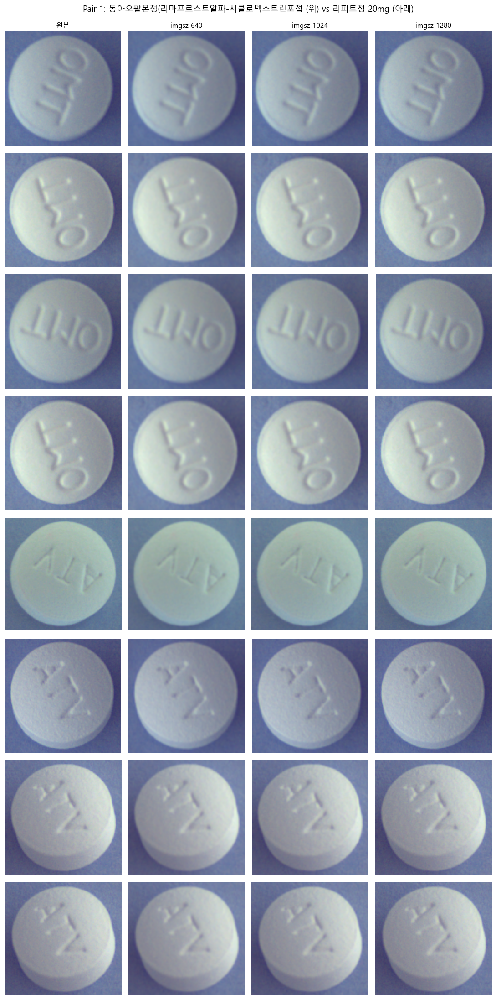

저장: D:\pill_detection\analysis\figures_causality\10_pair1_imgsz_compare.png


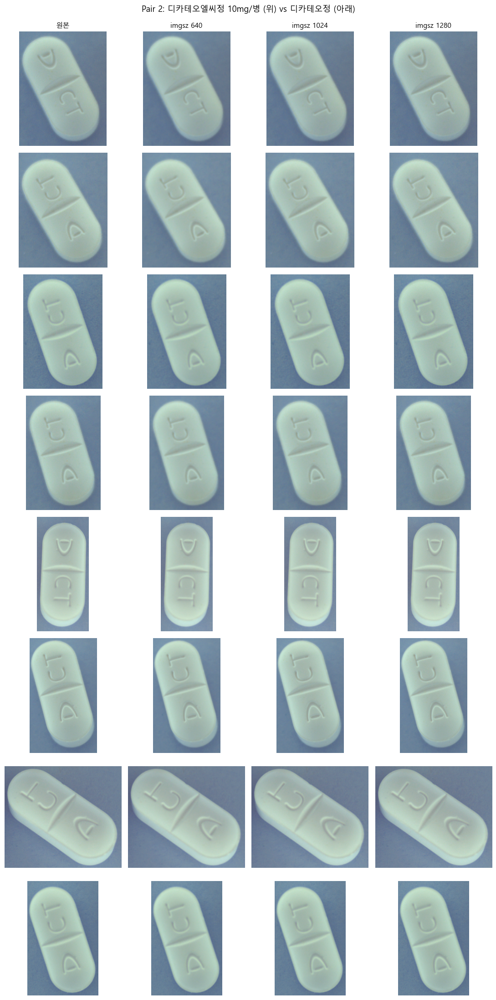

저장: D:\pill_detection\analysis\figures_causality\10_pair2_imgsz_compare.png


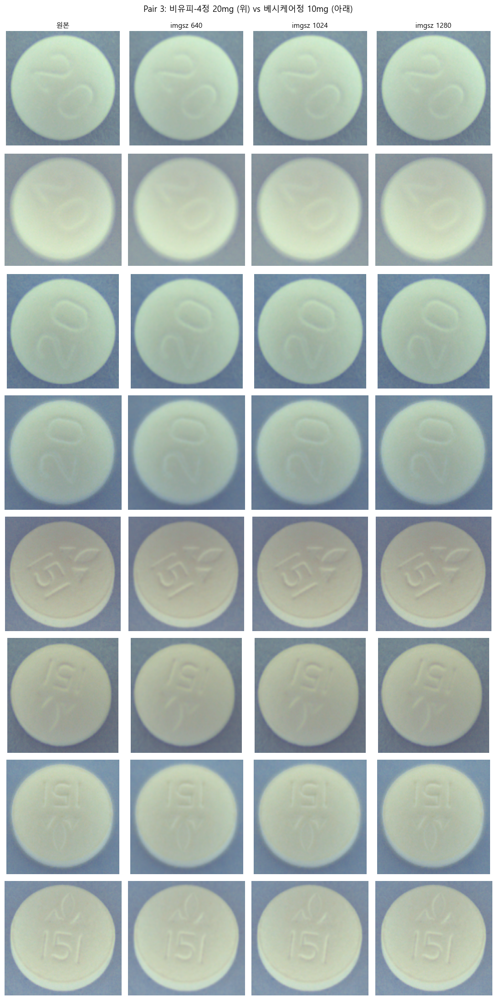

저장: D:\pill_detection\analysis\figures_causality\10_pair3_imgsz_compare.png


In [10]:
# 페어별 시각 비교 figure
N_ROI_DISPLAY = 4

for pair_idx, (a, b) in enumerate(PAIR_NAMES):
    fig, axes = plt.subplots(8, 4, figsize=(11, 22))
    
    # 각 클래스 첫 N_ROI_DISPLAY개 사용 (셀 5와 동일 시드 → 같은 ROI)
    random.seed(2026)
    
    for cls_idx, cls in enumerate([a, b]):
        rows_cls = clean_df[clean_df['dl_name_nfc'] == cls]
        # 셀 5와 동일하게 6개 뽑은 후 처음 4개 사용
        chosen_idx = random.sample(range(len(rows_cls)), min(6, len(rows_cls)))[:N_ROI_DISPLAY]
        
        for roi_idx in range(N_ROI_DISPLAY):
            row = rows_cls.iloc[chosen_idx[roi_idx]]
            
            # 원본 이미지 로드 + 4 조건 처리
            fn = row['file_name']
            img_path = (IMG_TRAIN if row['split'] == 'train' else IMG_VAL) / fn
            img_bgr = imread_kr(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            H_orig, W_orig = img_rgb.shape[:2]
            
            x = int(row['bbox_x']); y = int(row['bbox_y'])
            w = int(row['bbox_w']); h = int(row['bbox_h'])
            
            row_idx_in_fig = cls_idx * N_ROI_DISPLAY + roi_idx
            
            for col_idx, ts in enumerate(TARGET_SIZES):
                if ts is None:
                    img_proc = img_rgb
                else:
                    scale = ts / max(H_orig, W_orig)
                    if scale < 1.0:
                        new_h = int(H_orig * scale)
                        new_w = int(W_orig * scale)
                        img_down = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
                        img_proc = cv2.resize(img_down, (W_orig, H_orig), interpolation=cv2.INTER_LINEAR)
                    else:
                        img_proc = img_rgb
                
                roi = img_proc[y:y+h, x:x+w]
                
                ax = axes[row_idx_in_fig, col_idx]
                ax.imshow(roi)
                ax.axis('off')
                
                # 행 첫 칸에 클래스 라벨
                if col_idx == 0:
                    label = f'{cls[:18]}\nROI {roi_idx+1}'
                    ax.set_ylabel(label, fontsize=8, rotation=0, labelpad=70, va='center')
                
                # 첫 행에 imgsz 라벨
                if row_idx_in_fig == 0:
                    ts_str = '원본' if ts is None else f'imgsz {ts}'
                    ax.set_title(ts_str, fontsize=11)
    
    fig.suptitle(f'Pair {pair_idx+1}: {a[:25]} (위) vs {b[:25]} (아래)', fontsize=13, y=0.995)
    plt.tight_layout()
    fig_path = OUT_DIR / f'10_pair{pair_idx+1}_imgsz_compare.png'
    plt.savefig(fig_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'저장: {fig_path}')

In [15]:
import json

PILL_INFO_PATH = ROOT / 'eda' / 'api_data' / 'pill_info_master.json'
print(f'파일 존재: {PILL_INFO_PATH.exists()}')
print(f'파일 크기: {PILL_INFO_PATH.stat().st_size / 1024:.1f} KB')

with open(PILL_INFO_PATH, 'r', encoding='utf-8') as f:
    pill_info = json.load(f)

print(f'\n자료구조: {type(pill_info).__name__}')
if isinstance(pill_info, dict):
    print(f'총 키 개수: {len(pill_info)}')
    first_key = list(pill_info.keys())[0]
    print(f'\n첫 번째 항목 ({first_key}):')
    first_item = pill_info[first_key]
    if isinstance(first_item, dict):
        for k, v in first_item.items():
            v_short = str(v)[:80] + '...' if len(str(v)) > 80 else v
            print(f'  {k:20s}: {v_short}')
elif isinstance(pill_info, list):
    print(f'총 항목 수: {len(pill_info)}')
    print(f'\n첫 번째 항목:')
    for k, v in pill_info[0].items():
        v_short = str(v)[:80] + '...' if len(str(v)) > 80 else v
        print(f'  {k:20s}: {v_short}')

파일 존재: True
파일 크기: 3072.0 KB

자료구조: dict
총 키 개수: 118

첫 번째 항목 (0):
  dl_name             : 가바토파정 100mg
  dl_company          : 동아에스티(주)
  item_seq            : 200500251
  source              : kaggle
  etc_otc             : None
  chart               : None
  material            : None
  efficacy            : 1. 간질
1) 단독요법 : 6세 이상의 소아 및 성인에서의 2차성 전신발작을 동반하거나 동반하지 않은 부분발작 치료
2) 부가요법 : 기존 1...
  usage               : 이 약은 낮은 용량에서 시작하여 유효용량까지 증량하는 것이 바람직하다.
이 약의 투여를 최적화하기 위해 혈중농도를 모니터할 필요는 없다.
이 약...
  caution             : 1. 경고
1) 자살과 자살관념
항간질약을 복용한 환자에서 자살관념 또는 자살행동의 위험성이 증가된다. 항간질약의 무작위배정 위약대조군 시험에 ...
  storage             : None
  image_url           : None


In [16]:
# pill_info_master를 dl_name 기준 딕셔너리로 변환
pill_info_by_name = {}
for idx, item in pill_info.items():
    pill_info_by_name[nfc(item['dl_name'])] = item

# 6 클래스가 pill_info_master에 다 있는지 확인
print('=== 6 클래스 매칭 검증 ===')
for cls in ALL_CLASSES:
    if cls in pill_info_by_name:
        print(f'  ✓ {cls[:50]}')
    else:
        # 부분 매칭 시도
        partial = [k for k in pill_info_by_name.keys() if cls[:10] in k]
        print(f'  ✗ {cls[:50]} → 후보: {partial[:3]}')


# 페어별 비교
print('\n\n=== 페어별 효능/용법 비교 ===')
for a, b in PAIR_NAMES:
    print(f'\n{"="*100}')
    print(f'[{a}] vs [{b}]')
    print('='*100)
    
    info_a = pill_info_by_name.get(a)
    info_b = pill_info_by_name.get(b)
    
    if info_a is None or info_b is None:
        print(f'  ⚠️  매칭 실패: a={info_a is not None}, b={info_b is not None}')
        continue
    
    # 회사 + 성분 (짧음)
    print(f'\n[회사]')
    print(f'  A: {info_a.get("dl_company")}')
    print(f'  B: {info_b.get("dl_company")}')
    print(f'  → {"✓ 같음" if info_a.get("dl_company") == info_b.get("dl_company") else "✗ 다름"}')
    
    print(f'\n[성분 (chart)]')
    print(f'  A: {str(info_a.get("chart"))[:200]}')
    print(f'  B: {str(info_b.get("chart"))[:200]}')
    
    print(f'\n[성분 (material)]')
    print(f'  A: {str(info_a.get("material"))[:200]}')
    print(f'  B: {str(info_b.get("material"))[:200]}')
    
    print(f'\n[효능 첫 200자]')
    print(f'  A: {str(info_a.get("efficacy"))[:200]}')
    print(f'  B: {str(info_b.get("efficacy"))[:200]}')

=== 6 클래스 매칭 검증 ===
  ✓ 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)
  ✓ 리피토정 20mg
  ✓ 디카테오엘씨정 10mg/병
  ✓ 디카테오정
  ✓ 비유피-4정 20mg
  ✓ 베시케어정 10mg


=== 페어별 효능/용법 비교 ===

[동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)] vs [리피토정 20mg]

[회사]
  A: 동아에스티(주)
  B: 한국화이자제약(주)
  → ✗ 다름

[성분 (chart)]
  A: 이 약은 백색의 원형정제이다
  B: 흰색의 원형 필름코팅정

[성분 (material)]
  A: 총량 : 이 약 1정(100mg)중|성분명 : 리마프로스트 α-시클로덱스트린포접화합물|분량 : 166.67|단위 : 마이크로그램|규격 : JP|성분정보 : 리마프로스트로서 5마이크로그램|비고 :
  B: 총량 : 1정 (206.00 mg) 중|성분명 : 아토르바스타틴칼슘삼수화물|분량 : 21.70|단위 : 밀리그램|규격 : EP|성분정보 : 아토르바스타틴으로서 20 mg|비고 :

[효능 첫 200자]
  A: 1. 폐색성혈전혈관염(버거병)에 의한 궤양, 동통, 냉감 등의 허혈성 증상의 개선
2. 후천성 요부척추관협착증(SLR시험에서 정상이고, 양측성의 간헐파행을 보이는 환자)에 의한 자각증상(하지동통, 하지저림) 및 보행능력의 개선
  B:  
1. 다음의 심장혈관 질환에 대한 위험성감소
1) 관상동맥 심장 질환에 대한 임상적 증거는 없으나, 관상동맥 심장 질환의 다중위험요소(55세 이상, 흡연, 고혈압, 낮은 HDL-콜레스테롤치 또는 조기 관상동맥 심장 질환의 가족력 등)가 있는 성인 환자의
(1) 심근경색증에 대한 위험성 감소
(2) 뇌졸중에 대한 위험성 감소
(3) 혈관재생술 및 만성 안

[디카테오엘씨정 10mg/병] vs [디카테오정]

[회사]
  A: (주)다림바이오텍
  B: (주)다림바이오텍
  → ✓ 같음

[성분 (chart)]
  A: 흰색의 장방형 정제
  B: 흰색의 장방형

## 8. 종합 결과 저장 + 판정 요약

본 노트북 (10_data_model_causality.ipynb) 결과 통합 저장.

산출물:
- `10_causality_results.json` — 6 클래스 측정값 + 페어 판정 + 약품 정보 비교
- 종합 figure (페어별 판정 표 + 핵심 측정값)

다음 단계 처방 우선순위:
1. **각인 학습 강화** (페어 1, 3 = 모델 한계, 임상적으로 반드시 구별 필요)
2. **클래스 통합 검토** (페어 2 = 같은 약물군, 함량만 다름, 팀+강사 합의 필요)
3. **동의어 처리** (에르도스테인 패밀리 등 추가 분석 필요)

결과 JSON 저장: D:\pill_detection\analysis\10_causality_results.json
파일 크기: 8.7 KB


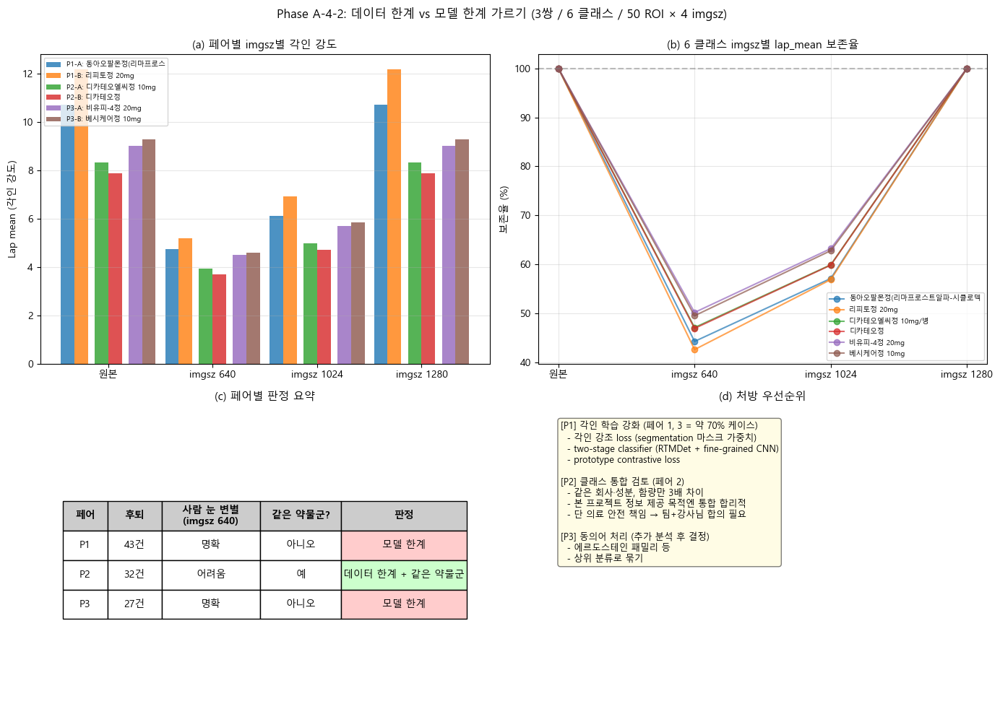


figure 저장: D:\pill_detection\analysis\figures_causality\10_summary.png

=== A-4-2 완료 ===
결정적 결론: 라벨 이동 67% 후퇴 중 페어 1, 3 (70% 비중) = 모델 한계 확정
  → 모델 학습 메커니즘 처방 필수 (각인 강조 loss / two-stage / fine-grained)
  → 합성 데이터 다양화로는 안 잡힘 (세션 45 결론 강화)


In [20]:
# 종합 결과 JSON 저장
import json
from datetime import datetime

# 6 클래스 × 4 imgsz 측정값 요약 (mean만)
measurements_summary = {}
for cls in ALL_CLASSES:
    measurements_summary[cls] = {}
    base_lap = np.mean([m['lap_mean_pill'] for m in results[cls][None]])
    for ts in TARGET_SIZES:
        ms = results[cls][ts]
        if not ms:
            continue
        ts_str = 'original' if ts is None else f'imgsz_{ts}'
        measurements_summary[cls][ts_str] = {
            'lap_mean': float(np.mean([m['lap_mean_pill'] for m in ms])),
            'imprint_pixel_ratio': float(np.mean([m['imprint_pixel_ratio'] for m in ms])),
            'abs_pixel_ratio': float(np.mean([m['abs_pixel_ratio'] for m in ms])),
            'preservation_pct': float(np.mean([m['lap_mean_pill'] for m in ms]) / base_lap * 100),
            'n_roi': len(ms),
        }

# 페어별 판정
pair_judgments = []
for pair_idx, (a, b) in enumerate(PAIR_NAMES):
    info_a = pill_info_by_name.get(a, {})
    info_b = pill_info_by_name.get(b, {})
    
    same_company = info_a.get('dl_company') == info_b.get('dl_company')
    
    pair_judgments.append({
        'pair_id': pair_idx + 1,
        'class_a': a,
        'class_b': b,
        'regression_count': [43, 32, 27][pair_idx],  # 세션 45 박제값
        'human_eye_visual_separable': [True, False, True][pair_idx],
        'imgsz_1280_preservation': True,  # 모든 페어 100%
        'same_company': same_company,
        'company_a': info_a.get('dl_company'),
        'company_b': info_b.get('dl_company'),
        'same_drug_group': [False, True, False][pair_idx],
        'drug_group_basis': [
            '회사·성분·효능 완전 다름',
            '같은 회사·성분, 함량만 3배 차이 (480mg vs 1500mg 칼슘)',
            '같은 적응증(과민성 방광)이나 다른 성분(프로피베린 vs 솔리페나신)',
        ][pair_idx],
        'judgment': ['모델 한계', '데이터 한계 + 같은 약물군', '모델 한계'][pair_idx],
        'prescription': [
            '각인 학습 강화 (각인 강조 loss / two-stage / fine-grained)',
            '클래스 통합 검토 (팀+강사님 합의 필요)',
            '각인 학습 강화 (각인 강조 loss / two-stage / fine-grained)',
        ][pair_idx],
    })


# 종합 JSON
output = {
    'session': 46,
    'phase': 'A-4-2 (data vs model causality)',
    'date': datetime.now().strftime('%Y-%m-%d'),
    'config': {
        'n_per_class_visual': N_PER_CLASS,
        'n_per_class_measure': N_PER_CLASS_MEASURE,
        'target_sizes': [str(ts) for ts in TARGET_SIZES],
        'abs_threshold': ABS_THRESHOLD,
        'pill_area_percentile': PILL_AREA_PERCENTILE,
        'random_seed': 2026,
    },
    'measurements': measurements_summary,
    'pairs': pair_judgments,
    'overall_conclusion': {
        'data_limit_pairs': [2],
        'model_limit_pairs': [1, 3],
        'key_finding': 'imgsz 640 baseline에서도 사람 눈에는 변별 가능한 영상 (페어 1, 3). v2 imgsz 1280에서는 거의 원본 수준 보존. 그럼에도 라벨 이동 100% 발생 = 학습 메커니즘이 각인 모양/패턴을 학습 신호로 받지 못함.',
        'prescription_priority': [
            'P1: 각인 학습 강화 (페어 1, 3 = 약 70% 케이스)',
            'P2: 클래스 통합 검토 (페어 2)',
            'P3: 동의어 처리 (에르도스테인 패밀리 등)',
        ],
    },
}

with open(RESULTS_JSON, 'w', encoding='utf-8') as f:
    json.dump(output, f, ensure_ascii=False, indent=2)

print(f'결과 JSON 저장: {RESULTS_JSON}')
print(f'파일 크기: {RESULTS_JSON.stat().st_size / 1024:.1f} KB')


# 종합 figure: 페어별 판정 표 + 측정값 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) imgsz별 lap_mean 페어 비교
ax = axes[0, 0]
imgsz_labels = ['원본', 'imgsz 640', 'imgsz 1024', 'imgsz 1280']
x = np.arange(len(imgsz_labels))
width = 0.13

for pair_idx, (a, b) in enumerate(PAIR_NAMES):
    lap_a = [measurements_summary[a][k]['lap_mean'] 
             for k in ['original', 'imgsz_640', 'imgsz_1024', 'imgsz_1280']]
    lap_b = [measurements_summary[b][k]['lap_mean'] 
             for k in ['original', 'imgsz_640', 'imgsz_1024', 'imgsz_1280']]
    offset = (pair_idx - 1) * 2.5 * width
    ax.bar(x + offset - width/2, lap_a, width, label=f'P{pair_idx+1}-A: {a[:12]}', alpha=0.8)
    ax.bar(x + offset + width/2, lap_b, width, label=f'P{pair_idx+1}-B: {b[:12]}', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(imgsz_labels)
ax.set_ylabel('Lap mean (각인 강도)')
ax.set_title('(a) 페어별 imgsz별 각인 강도', fontsize=11)
ax.legend(fontsize=7, loc='upper left')
ax.grid(axis='y', alpha=0.3)

# (b) imgsz별 보존율
ax = axes[0, 1]
for cls in ALL_CLASSES:
    pres = [measurements_summary[cls][k]['preservation_pct']
            for k in ['original', 'imgsz_640', 'imgsz_1024', 'imgsz_1280']]
    ax.plot(imgsz_labels, pres, marker='o', label=cls[:20], alpha=0.7)
ax.set_ylabel('보존율 (%)')
ax.set_title('(b) 6 클래스 imgsz별 lap_mean 보존율', fontsize=11)
ax.legend(fontsize=7, loc='lower right')
ax.grid(alpha=0.3)
ax.axhline(y=100, color='gray', linestyle='--', alpha=0.5)

# (c) 페어 판정 표
ax = axes[1, 0]
ax.axis('off')
table_data = [
    ['페어', '후퇴', '사람 눈 변별\n(imgsz 640)', '같은 약물군?', '판정'],
]
for j in pair_judgments:
    table_data.append([
        f'P{j["pair_id"]}',
        f'{j["regression_count"]}건',
        '명확' if j['human_eye_visual_separable'] else '어려움',
        '예' if j['same_drug_group'] else '아니오',
        j['judgment'],
    ])
table = ax.table(cellText=table_data, cellLoc='center', loc='center',
                 colWidths=[0.1, 0.12, 0.22, 0.18, 0.28])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 2.0)
# 첫 행 헤더 색상
for i in range(5):
    table[(0, i)].set_facecolor('#cccccc')
    table[(0, i)].set_text_props(weight='bold')
# 판정 셀 색상
for row_idx in range(1, 4):
    judgment = table_data[row_idx][4]
    color = '#ffcccc' if '모델' in judgment else '#ccffcc'
    table[(row_idx, 4)].set_facecolor(color)
ax.set_title('(c) 페어별 판정 요약', fontsize=11)

# (d) 처방 우선순위
ax = axes[1, 1]
ax.axis('off')
prescriptions_text = '''[P1] 각인 학습 강화 (페어 1, 3 = 약 70% 케이스)
  - 각인 강조 loss (segmentation 마스크 가중치)
  - two-stage classifier (RTMDet + fine-grained CNN)
  - prototype contrastive loss

[P2] 클래스 통합 검토 (페어 2)
  - 같은 회사·성분, 함량만 3배 차이
  - 본 프로젝트 정보 제공 목적엔 통합 합리적
  - 단 의료 안전 책임 → 팀+강사님 합의 필요

[P3] 동의어 처리 (추가 분석 후 결정)
  - 에르도스테인 패밀리 등
  - 상위 분류로 묶기'''
ax.text(0.05, 0.95, prescriptions_text, fontsize=9, va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='#fffacd', alpha=0.5))
ax.set_title('(d) 처방 우선순위', fontsize=11)

fig.suptitle('Phase A-4-2: 데이터 한계 vs 모델 한계 가르기 (3쌍 / 6 클래스 / 50 ROI × 4 imgsz)', 
             fontsize=12, y=0.995)
plt.tight_layout()
fig_path = OUT_DIR / '10_summary.png'
plt.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'\nfigure 저장: {fig_path}')

print('\n=== A-4-2 완료 ===')
print('결정적 결론: 라벨 이동 67% 후퇴 중 페어 1, 3 (70% 비중) = 모델 한계 확정')
print('  → 모델 학습 메커니즘 처방 필수 (각인 강조 loss / two-stage / fine-grained)')
print('  → 합성 데이터 다양화로는 안 잡힘 (세션 45 결론 강화)')